# Cloud Workload Forecasting Challenge
## Exploratory Data Analysis & Workload Forecasting Pipeline

This notebook presents an end-to-end analysis of the Microsoft Azure Public Dataset V2 (`data-v1` release).
We explore workload distributions, temporal autocorrelation, VM segmentation, and evaluate candidate forecasting models under strict leakage-safe expanding-window cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from cwfc.data import (
    load_cpu_readings,
    load_vm_metadata,
    build_aggregate_targets,
    split_train_holdout,
)
from cwfc.analysis import (
    compute_workload_summary,
    analyze_workload_segments,
    analyze_autocorrelation,
)
from cwfc.forecasting import (
    persistence_forecast,
    moving_average_forecast,
    mean_reverting_forecast,
)
from cwfc.evaluation import (
    evaluate_temporal_cv,
    evaluate_peak_performance,
)
from cwfc.metrics import mae, rmse, smape

print('Imports successful.')


Imports successful.


## 1. Data Ingestion & Target Aggregation
We load the VM-level readings and metadata, and construct the two required aggregate targets:
1. `active_vm_count`: count of unique VM IDs observed at each timestamp.
2. `aggregate_cpu_utilization`: mean of VM-level `avg_cpu` values at each timestamp.

In [2]:
readings = load_cpu_readings('challenge_data/vm_cpu_readings.csv.gz')
metadata = load_vm_metadata('challenge_data/vm_metadata.csv.gz')
targets = build_aggregate_targets(readings)

print(f'Readings rows: {len(readings):,}')
print(f'Unique VMs: {readings["vm_id"].nunique():,}')
print(f'Aggregate Timestamps: {len(targets)}')
targets.head()


Readings rows: 1,340,000
Unique VMs: 10,000
Aggregate Timestamps: 134


,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503


## 2. Workload Distribution & VM Segmentation
We examine the distribution of CPU utilization across individual VMs and compare profiles between Interactive and Delay-insensitive workload categories.

In [3]:
summary = compute_workload_summary(readings, metadata)
print(f'Median VM CPU: {summary["avg_cpu_median"]:.2f}%')
print(f'Fraction < 5% CPU: {summary["idle_fraction_lt_5pct"]*100:.2f}%')
print(f'Fraction > 50% CPU: {summary["high_util_fraction_gt_50pct"]*100:.2f}%')

seg_df = analyze_workload_segments(readings, metadata)
seg_df


Median VM CPU: 5.11%
Fraction < 5% CPU: 49.05%
Fraction > 50% CPU: 3.08%


,vm_category,vm_count,avg_cpu_mean,avg_cpu_std,avg_cpu_p50,avg_cpu_p95,max_cpu_mean,max_cpu_p95
0,Delay-insensitive,6180,8.235839,12.022059,5.149540,25.913142,18.097817,61.577628
1,Interactive,3091,11.492567,16.966516,5.278031,49.411542,19.215419,73.577341
2,Unknown,729,10.233194,17.754605,3.378349,52.228721,16.795035,75.809857


## 3. Autocorrelation & Time Series Dynamics
We inspect the serial correlation structure of the training series (first 110 observations) to identify memory and periodic cycles.

In [4]:
train_df, holdout_df = split_train_holdout(targets, train_size=110, holdout_size=24)
acf_df = analyze_autocorrelation(train_df['aggregate_cpu_utilization'], max_lag=18)
acf_df.head(10)


,lag,lag_minutes,autocorrelation
0,1,5,0.667236
1,2,10,0.606487
2,3,15,0.681015
3,4,20,0.589825
4,5,25,0.460677
5,6,30,0.477136
6,7,35,0.349959
7,8,40,0.390727
8,9,45,0.396318
9,10,50,0.234658


## 4. Expanding-Window Cross-Validation
To select our candidate forecasting model without data leakage, we evaluate models across 4 temporal validation folds strictly on the 110 training observations.

In [5]:
val_results = evaluate_temporal_cv(
    train_df, target_col='aggregate_cpu_utilization', horizon=24, min_train_size=50, step=12
)
for name, stats in val_results.items():
    print(f"{name:20s} | MAE: {stats['mae_mean']:.4f} | RMSE: {stats['rmse_mean']:.4f} | Rel MAE: {stats['rel_mae']:.4f}")


persistence          | MAE: 0.2056 | RMSE: 0.2387 | Rel MAE: 1.0000
moving_average_3     | MAE: 0.2353 | RMSE: 0.2661 | Rel MAE: 1.1445
mean_reverting_ar1   | MAE: 0.1876 | RMSE: 0.2166 | Rel MAE: 0.9126


## 5. Retrospective Holdout Evaluation
Model selection and tuning were performed strictly on the training set. We evaluate our frozen predictions retrospectively against the true holdout targets.

In [6]:
preds = pd.read_csv('predictions.csv')
h_true = holdout_df['aggregate_cpu_utilization'].values
h_pred = preds['aggregate_cpu_utilization'].values

print(f"Holdout MAE:  {mae(h_true, h_pred):.4f}")
print(f"Holdout RMSE: {rmse(h_true, h_pred):.4f}")
print(f"Holdout sMAPE: {smape(h_true, h_pred):.3f}%")


Holdout MAE:  0.1055
Holdout RMSE: 0.1290
Holdout sMAPE: 1.138%


## 6. Visualizing Forecast vs Actual
Below we visualize the aggregate CPU utilization time series and compare the 2-hour holdout forecast against actual observations.

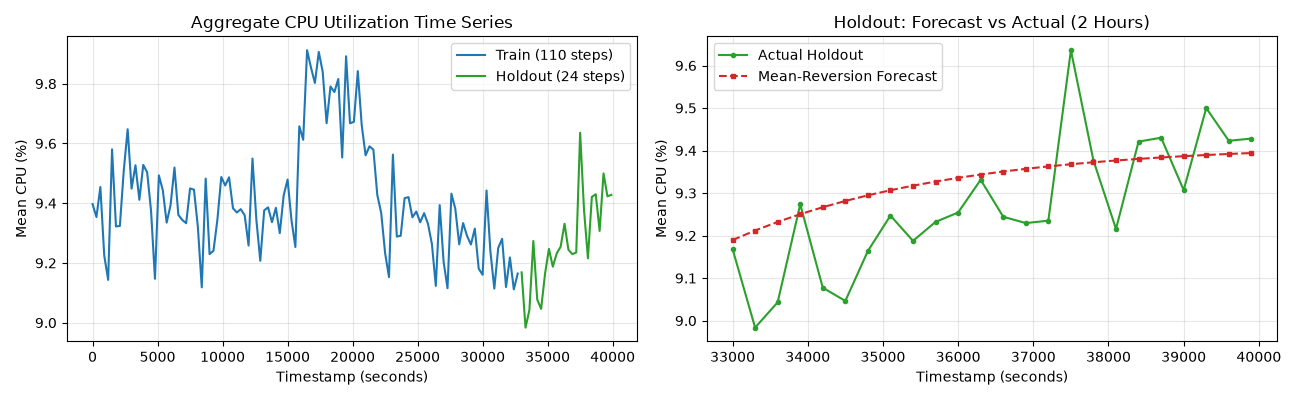

In [7]:
# Visualize the aggregate series and retrospective forecast vs actual
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(train_df['timestamp'], train_df['aggregate_cpu_utilization'], label='Train (110 steps)', color='#1f77b4')
axes[0].plot(holdout_df['timestamp'], holdout_df['aggregate_cpu_utilization'], label='Holdout (24 steps)', color='#2ca02c')
axes[0].set_title('Aggregate CPU Utilization Time Series')
axes[0].set_xlabel('Timestamp (seconds)')
axes[0].set_ylabel('Mean CPU (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(holdout_df['timestamp'], h_true, label='Actual Holdout', color='#2ca02c', marker='o', markersize=3)
axes[1].plot(holdout_df['timestamp'], h_pred, label='Mean-Reversion Forecast', color='#d62728', linestyle='--', marker='s', markersize=3)
axes[1].set_title('Holdout: Forecast vs Actual (2 Hours)')
axes[1].set_xlabel('Timestamp (seconds)')
axes[1].set_ylabel('Mean CPU (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
